# 18 · SIFT: Parameters and Cost

LRT4012 Robot Vision · Fall 2026


## SIFT: scale-space extrema and gradient descriptors

$$L(x,y,\sigma)=G_\sigma*I,\qquad D(x,y,\sigma)=L(x,y,k\sigma)-L(x,y,\sigma).$$

$I$ is the input image, $(x,y)$ are pixel coordinates, $G_\sigma$ is a normalized Gaussian kernel with standard deviation $\sigma$, $*$ denotes convolution, $L$ is the smoothed image, $k>1$ is the adjacent scale ratio, and $D$ is the Difference of Gaussians. SIFT refines extrema, rejects weak or edge-dominated candidates, assigns dominant gradient orientation and forms a 128-component descriptor.

`contrastThreshold` rejects weak responses; `edgeThreshold` controls rejection of edge-like responses (a larger value retains more); `nOctaveLayers` samples scale and `sigma` sets initial smoothing. Detection is only approximately robust to scale and rotation, with limits under viewpoint and illumination changes.

SURF is a related method based on approximate Hessian responses and Haar-wavelet descriptors. Its implementation is outside the required course environment; the executable comparison uses SIFT and ORB.


In [1]:
from pathlib import Path
import os, time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repository():
    candidates = []
    if os.environ.get('VISION_ROBOTICA_REPO'):
        candidates.append(Path(os.environ['VISION_ROBOTICA_REPO']).expanduser())
    candidates += [Path.cwd(), *Path.cwd().parents]
    for root in candidates:
        if (root / 'requirements.txt').is_file() and (root / 'imagenes').is_dir():
            return root.resolve()
    raise FileNotFoundError('Open Jupyter inside the course repository, or set VISION_ROBOTICA_REPO to its root.')

REPO = find_repository()
IMAGE_DIR = REPO / 'imagenes'  # Read-only official resources.
# Save your own notebook and generated images in student_work/ and student_work/imagenes/.
cv2.setRNGSeed(4012)
cv2.setNumThreads(1)
rng = np.random.default_rng(4012)
plt.rcParams.update({'figure.dpi':100, 'font.size':10})

def load_image(name, max_side=640):
    image = cv2.imread(str(IMAGE_DIR / name), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f'Official resource could not be read: {name}')
    h, w = image.shape[:2]
    if max(h, w) > max_side:
        scale = max_side / max(h, w)
        image = cv2.resize(image, (round(w*scale), round(h*scale)), interpolation=cv2.INTER_AREA)
    return image

def gray(image): return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

def panels(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(4*len(images), 3.5), squeeze=False)
    for ax, im, title in zip(axes[0], images, titles):
        if im.ndim == 3:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(im, cmap='gray', vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis('off')
    fig.tight_layout()
    plt.show()

def timed_ms(fn, repetitions=30):
    fn()  # Warm-up.
    times = []
    for _ in range(repetitions):
        start = time.perf_counter()
        fn()
        times.append((time.perf_counter()-start)*1000)
    return float(np.median(times))

def mask_metrics(prediction, reference):
    a, b = prediction.astype(bool), reference.astype(bool)
    tp = int(np.count_nonzero(a & b))
    fp = int(np.count_nonzero(a & ~b))
    fn = int(np.count_nonzero(~a & b))
    return {'IoU': tp/(tp+fp+fn) if tp+fp+fn else 1.0,
            'precision': tp/(tp+fp) if tp+fp else np.nan,
            'recall': tp/(tp+fn) if tp+fn else np.nan,
            'F1': 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 1.0}


,threshold,keypoints,descriptor_bytes,median_ms
0,0.01,600,307200,29.513
1,0.04,600,307200,27.557
2,0.10,334,171008,21.796


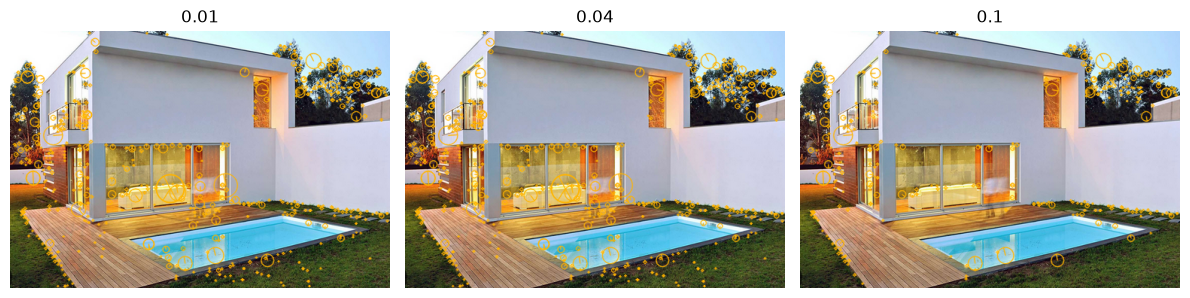

In [2]:
image=load_image('casa.png'); g=gray(image)
rows=[]; views=[]
for threshold in [0.01,0.04,0.10]:
    detector=cv2.SIFT_create(nfeatures=600,contrastThreshold=threshold)
    points,descriptors=detector.detectAndCompute(g,None)
    rows.append({'threshold':threshold,'keypoints':len(points),'descriptor_bytes':0 if descriptors is None else descriptors.nbytes,
                 'median_ms':timed_ms(lambda:detector.detectAndCompute(g,None))})
    views.append(cv2.drawKeypoints(image,points,None,color=(0,180,255),flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS))
display(pd.DataFrame(rows).round(3))
panels(views,[str(v) for v in [0.01,0.04,0.10]])


## Robotic interpretation

Choose a threshold based on spatial coverage and processing cost. Use notebook 19 to validate matching quality before recommending it for a robot. Explain why descriptor memory and point count are distinct from accuracy.


## References

- [OpenCV: Harris](https://docs.opencv.org/4.x/dc/d0d/tutorial_py_features_harris.html)
- [OpenCV: ORB parameters](https://docs.opencv.org/4.13.0/db/d95/classcv_1_1ORB.html)
- [OpenCV: SIFT](https://docs.opencv.org/4.x/da/df5/tutorial_py_sift_intro.html)
